In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
from sklearn.model_selection import train_test_split
import torch
from tqdm import tqdm
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset
import torch.nn.functional as F
import pandas as pd
from scipy.spatial.distance import euclidean
import numpy as np
import time
import matplotlib.pyplot as plt
from torch.nn import Module
from sklearn.metrics import r2_score
import os

In [127]:
class CNN_GRU_Model(nn.Module):
    def __init__(self, time_lag=72, pred_horizon=4, num_stations=9, gru_layers=2):
        super(CNN_GRU_Model, self).__init__()

        self.pred_horizon = pred_horizon
        self.num_stations = num_stations

        # 3D Convolution Layer
        cnn_out_channels = 64
        self.conv3d = nn.Conv3d(in_channels=1, out_channels=cnn_out_channels, kernel_size=(1, number_of_similars, 1))
        self.activation = nn.SELU()

        # GRU Layer
        hidden_size=64 * num_stations * pred_horizon
        self.gru = nn.GRU(input_size=num_stations*cnn_out_channels, hidden_size=hidden_size, num_layers=gru_layers, batch_first=True, dropout=0.02)

        # Fully connected layer for main model output
        fc_main_output_size = 300*pred_horizon
        self.fc_main = nn.Linear(hidden_size, fc_main_output_size)

        # Fully connected layer for auxiliary input (72, 3) -> flattened and mapped to 100 neurons
        aux_data_len=3
        fc_aux_output_size=2*time_lag
        self.fc_aux = nn.Linear(time_lag * aux_data_len, fc_aux_output_size)

        # Fully connected layer after concatenating the main and aux inputs
        fc_concat1_output_size = 200*pred_horizon
        fc_concat2_output_size = 100*pred_horizon
        fc_concat3_output_size = 50*pred_horizon
        self.fc_concat1 = nn.Linear(fc_main_output_size+fc_aux_output_size, fc_concat1_output_size)
        self.fc_concat2 = nn.Linear(fc_concat1_output_size, fc_concat2_output_size)
        self.fc_concat3 = nn.Linear(fc_concat2_output_size, fc_concat3_output_size)
        self.fc_concat4 = nn.Linear(fc_concat3_output_size, num_stations * pred_horizon)


    def forward(self, x, aux_input):
        # Main model (CNN + GRU)
        x = x.unsqueeze(1)  # Shape: (batch_size, 1, 9, 4, 12)
        x = self.conv3d(x)  # Shape: (batch_size, 64, 9, 1, 12)
        x = self.activation(x)
        x = x.permute(0, 4, 1, 2, 3).contiguous()  # Shape: (batch_size, 12, 64, 9, 1)
        x = x.view(x.size(0), x.size(1), -1)  # Shape: (batch_size, 12, 64 * 9)
        x, _ = self.gru(x)  # Shape: (batch_size, time_lag, hidden_size)
        x = x[:, -1, :]  # Take the last time step's output -> Shape: (batch_size, hidden_size)
        x = self.fc_main(x)  # Shape: (batch_size, 250)

        # Auxiliary input processing (flatten first)
        aux_input = aux_input.view(aux_input.size(0), -1)  # Flatten (batch_size, 72 * 3)
        aux_out = self.fc_aux(aux_input)  # Shape: (batch_size, 100)
        aux_out = self.activation(aux_out)

        # Concatenate the main model output and auxiliary input
        combined = torch.cat((x, aux_out), dim=1)  # Shape: (batch_size, 250 + 100)

        # Final fully connected layer to get output (batch_size, 9 * 5)
        output = self.fc_concat1(combined)  # Shape: (batch_size, 9 * 5)
        output = self.activation(output)
        output = self.fc_concat2(output)
        output = self.activation(output)
        output = self.fc_concat3(output)
        output = self.activation(output)
        output = self.fc_concat4(output)
        output = output.view(output.size(0), self.num_stations, self.pred_horizon)  # Reshape to (batch_size, 9, 5)

        return output

    def train_model_early_stop(self, num_epochs, train_loader, valid_loader, batch_size, optimizer, criterion, device, patience=3):
        last_valid_loss = float('inf')
        epochs_no_improve = 0
        early_stop = False

        train_loss_history = []
        val_loss_history = []
        start_time = time.time()
        trained_epochs = 0

        for epoch in range(num_epochs):
            if early_stop:
                break
            trained_epochs += 1
            train_epoch_iterator = tqdm(train_loader, desc="Training")
            epoch_loss = self.train_epoch(train_epoch_iterator, optimizer, criterion, device)
            val_loss = self.get_eval_factors(valid_loader, batch_size, criterion, device)
            r2_scores = self.calculate_r2_score(valid_loader)

            train_loss_history += [epoch_loss]
            val_loss_history += [val_loss]
            print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {epoch_loss:.4f}, Val Loss: {val_loss:.4f}, R2_Score: {sum(r2_scores)/len(r2_scores):.4f}')

        # Early stopping
            if val_loss < last_valid_loss:
                last_valid_loss = val_loss
                epochs_no_improve = 0
                best_model_wts = self.state_dict()
            else:
                epochs_no_improve += 1

            if epochs_no_improve >= patience:
                print(f'Early stopping triggered after {epoch+1} epochs')
                early_stop = True

        end_time = time.time()
        training_time = end_time - start_time
        print(f'Total Training Time: {training_time:.2f} seconds')

        if early_stop:
            self.load_state_dict(best_model_wts)

        return (train_loss_history, val_loss_history, trained_epochs)

    def train_epoch(self, train_loader, optimizer, criterion, device):
        self.train()
        running_loss = 0.0
        total_samples = 0


        for inputs, aux_inputs, targets in train_loader:
            inputs, aux_inputs, targets = inputs.to(device), aux_inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = self(inputs, aux_inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * targets.size(0)
            total_samples += targets.size(0)
            train_loader.set_postfix({'train loss': loss.item()})

        epoch_loss = running_loss / total_samples
        return epoch_loss

    def get_eval_factors(self, val_loader, batch_size, criterion, device):
        self.eval()
        total_loss = 0
        total_samples = 0

        with torch.no_grad():
            for inputs, aux_inputs, targets in val_loader:
                inputs, aux_inputs, targets = inputs.to(device), aux_inputs.to(device), targets.to(device)
                outputs = model(inputs, aux_inputs)
                loss = criterion(outputs, targets)

                total_loss += loss.item() * targets.size(0)
                total_samples += targets.size(0)

        val_loss = total_loss / total_samples

        return val_loss

    def calculate_r2_score(self, val_loader):
        self.eval()

        all_targets = []
        all_predictions = []

        with torch.no_grad():
            for inputs, aux_inputs, targets in val_loader:
                inputs, aux_inputs, targets = inputs.to(device), aux_inputs.to(device), targets.to(device)
                outputs = model(inputs, aux_inputs)
                all_predictions.append(outputs.squeeze(-1).cpu())
                all_targets.append(targets.cpu())

        all_predictions = torch.cat(all_predictions, dim=0)
        all_targets = torch.cat(all_targets, dim=0)

        r2_scores = []
        for i in range(self.num_stations):
            pred = all_predictions[:, i].numpy()
            actual = all_targets[:, i].numpy()
            r2 = r2_score(actual, pred)
            r2_scores.append(r2)
        return r2_scores

In [115]:
def calculate_dtw(df1, df2):
    series1 = df1.to_numpy()
    series2 = df2.to_numpy()

    distance, _ = fastdtw(series1, series2, dist=euclidean)
    return distance

def append_time_if_missing(date_str):
    if len(date_str) == 10:  # 'yy-mm-dd' has a length of 10
        return date_str + ' 00:00:00'
    else:
        return date_str

def remove_outliers(lower_bound, upper_bound, df):
    outliers_count = ((df['PM2.5'] < lower_bound) | (df['PM2.5'] > upper_bound)).sum()
    df['PM2.5'] = df['PM2.5'].where((df['PM2.5'] >= lower_bound) & (df['PM2.5'] <= upper_bound), np.nan)
    df['PM2.5'] = df['PM2.5'].ffill().bfill()
    print(f"Number of outliers replaced: {outliers_count}")

def prepare_data(df, aux_df, time_lag=12, pred_horizon=5, num_stations=9):
    df['PM2.5'] = (df['PM2.5'] - df['PM2.5'].min()) / (df['PM2.5'].max() - df['PM2.5'].min())

    for column in aux_df.columns:
      if column != 'date':
        aux_df[column] = (aux_df[column] - aux_df[column].min()) / (aux_df[column].max() - aux_df[column].min())

    pm25_data = df['PM2.5'].values
    station_counts = df['Station'].value_counts()
    total_data = station_counts[1]

    inputs = []
    outputs = []
    aux_inputs = []
    aux_data = []

    for index, row in aux_df.iterrows():
      row_values = row.tolist()
      aux_data.append(row_values[1:])

    print(f"auxilary data length: {len(aux_data)}")
    print(f"PM2.5 data length: {total_data}")

    for i in range(0, total_data - time_lag - pred_horizon + 1, 1):
        input = []
        output = []
        for j in range(num_stations):
          inp = []
          out = []
          # np.append(similars[j], j + 1)
          for k in similars[j][1:number_of_similars + 1]:
            inp.append(pm25_data[(k - 1) * total_data + i:(k - 1) * total_data + i + time_lag])
            out.append(pm25_data[(k - 1) * total_data + i + time_lag:(k - 1) * total_data + i + time_lag + pred_horizon])
          input.append(inp)
          output.append(out[-1])
        inputs.append(input)
        outputs.append(output)
        aux_slice = aux_data[i:i + time_lag]
        aux_inputs.append(np.array(aux_slice))

    inputs = np.array(inputs)
    outputs = np.array(outputs)
    aux_inputs = np.array(aux_inputs)
    return inputs, outputs, aux_inputs

In [4]:
class PM25Dataset(Dataset):
    def __init__(self, x_data, aux_data, y_data, transform=None):
        self.x_data = x_data
        self.aux_data = aux_data
        self.y_data = y_data
        self.transform = transform

    def __len__(self):
        return len(self.x_data)

    def __getitem__(self, idx):
        x = self.x_data[idx]
        aux = self.aux_data[idx]
        y = self.y_data[idx]

        if self.transform:
            x = self.transform(x)

        return torch.tensor(x, dtype=torch.float32), torch.tensor(aux, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

In [5]:
base_address = '/content/drive/MyDrive/air pollution research'

In [6]:
# read pm25 dataframe, replace outliers
df =  pd.read_csv(os.path.join(base_address, 'PM2.5_preprocessed_data.csv'))
df = df.sort_values(by=['Station', 'Date'], ascending=[True, True])

lower_bound = 4
upper_bound = 96

remove_outliers(lower_bound, upper_bound, df)

Number of outliers replaced: 15438


In [7]:
similars_df = pd.read_csv(os.path.join(base_address, 'PM2.5 similarity ranks.csv'))
similars = similars_df.to_numpy()
print(similars)

[[1 1 2 8 4 3 9 5 7 6]
 [2 2 1 4 8 9 3 5 6 7]
 [3 3 7 9 4 8 5 2 1 6]
 [4 4 2 8 1 3 5 9 6 7]
 [5 5 7 3 4 9 2 6 8 1]
 [6 6 4 5 2 3 7 9 8 1]
 [7 7 3 9 5 4 6 8 2 1]
 [8 8 2 1 4 3 9 7 5 6]
 [9 9 7 3 4 8 2 5 1 6]]


In [8]:
# read aux dataframe, choose similar dates, fill nans

aux_df = pd.read_csv(os.path.join(base_address, 'IsfMet.csv'))
aux_df['date'] = aux_df['date'].apply(append_time_if_missing)
aux_df = aux_df[aux_df['date'].isin(df['Date'])]
aux_df = aux_df[['date', 'ws', 'wd', 'air_temp']]
aux_df = aux_df.ffill().bfill()

In [9]:
time_lag = 72
pred_horizon = 1
num_epochs = 80
batch_size = 32
number_of_similars = 5

In [10]:
# create datasets

inputs, outputs, aux = prepare_data(df, aux_df, time_lag, pred_horizon)

train_inputs, temp_inputs, train_outputs, temp_outputs, train_aux, temp_aux = train_test_split(inputs, outputs, aux, test_size=0.2, random_state=42, shuffle=True)
val_inputs, test_inputs, val_outputs, test_outputs, val_aux, test_aux = train_test_split(temp_inputs, temp_outputs, temp_aux, test_size=0.5, random_state=42, shuffle=True)

print(f"Shape of pm2.5 data: {train_inputs[0].shape}")
print(f"Shape of aux data: {train_aux[0].shape}")

auxilary data length: 23470
PM2.5 data length: 23470
Shape of pm2.5 data: (9, 5, 72)
Shape of aux data: (72, 3)


In [11]:
# Create TensorDataset and DataLoader for training and validation
train_dataset = PM25Dataset(train_inputs, train_aux, train_outputs)
val_dataset = PM25Dataset(val_inputs, val_aux, val_outputs)
test_dataset = PM25Dataset(test_inputs, test_aux, test_outputs)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [12]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [13]:
# Define model, loss function, and optimizer
model = CNN_GRU_Model(time_lag=time_lag, pred_horizon=pred_horizon)
model = model.to(device)
criterion = nn.L1Loss()
learning_rate = 0.01
momentum = 0.9

# # Initialize the optimizer with SGD and momentum
optimizer = optim.SGD(model.parameters(), lr=learning_rate, momentum=momentum)
# optimizer = optim.Adam(model.parameters(), lr=0.001)

In [23]:
(train_loss_history, val_loss_history, trained_epochs) = model.train_model_early_stop(num_epochs, train_loader, val_loader,
                                                                                      batch_size, optimizer, criterion, device, patience=1)

Training: 100%|██████████| 585/585 [00:16<00:00, 35.00it/s, train loss=0.0366]


Epoch [1/80], Train Loss: 0.0447, Val Loss: 0.0425, R2_Score: 0.8973


Training: 100%|██████████| 585/585 [00:16<00:00, 34.53it/s, train loss=0.041]


Epoch [2/80], Train Loss: 0.0445, Val Loss: 0.0441, R2_Score: 0.8923
Early stopping triggered after 2 epochs
Total Training Time: 36.68 seconds


In [24]:
print(sum(model.calculate_r2_score(test_loader)) / 9)

0.883830381764306


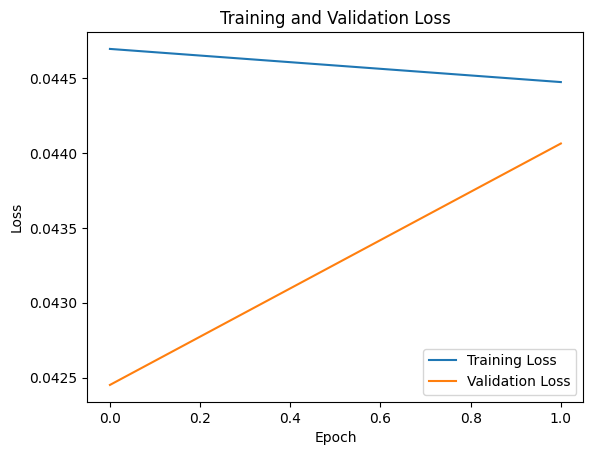

In [25]:
plt.figure()
plt.plot(train_loss_history, label='Training Loss')
plt.plot(val_loss_history, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

In [26]:
model.eval()

idx = 3
aux_single = train_aux[idx]
single_input = train_inputs[idx]  # Shape: (9, 4, 12)
aux_single = torch.tensor(aux_single, dtype=torch.float32)
single_input = torch.tensor(single_input, dtype=torch.float32)

# Add a batch dimension since the model expects a batch
aux_single = aux_single.unsqueeze(0)  # Shape: (1, 9, 4, 12)
single_input = single_input.unsqueeze(0)  # Shape: (1, 9, 4, 12)

# Make sure no gradients are computed during inference
aux_single = aux_single.to(device)
single_input = single_input.to(device)
with torch.no_grad():
    prediction = model(single_input, aux_single)

# `prediction` now contains the output for this single input
print("Prediction:", prediction)
print("Real:", train_outputs[idx])

Prediction: tensor([[[0.6828],
         [0.6665],
         [0.2960],
         [0.6890],
         [0.6829],
         [0.6806],
         [0.5994],
         [0.6857],
         [0.2836]]], device='cuda:0')
Real: [[0.64793478]
 [0.39141304]
 [0.30967391]
 [0.64793478]
 [0.39141304]
 [0.64793478]
 [0.63043478]
 [0.64793478]
 [0.30967391]]


In [27]:
r2_scores = model.calculate_r2_score(test_loader)

for i, r2 in enumerate(r2_scores):
    print(f'R² for station {i+1}: {r2:.4f}')

print(f'Mean of R² scores: {sum(r2_scores)/len(r2_scores):.4f}')


R² for station 1: 0.9198
R² for station 2: 0.8925
R² for station 3: 0.8957
R² for station 4: 0.9188
R² for station 5: 0.8928
R² for station 6: 0.9189
R² for station 7: 0.7007
R² for station 8: 0.9189
R² for station 9: 0.8963
Mean of R² scores: 0.8838


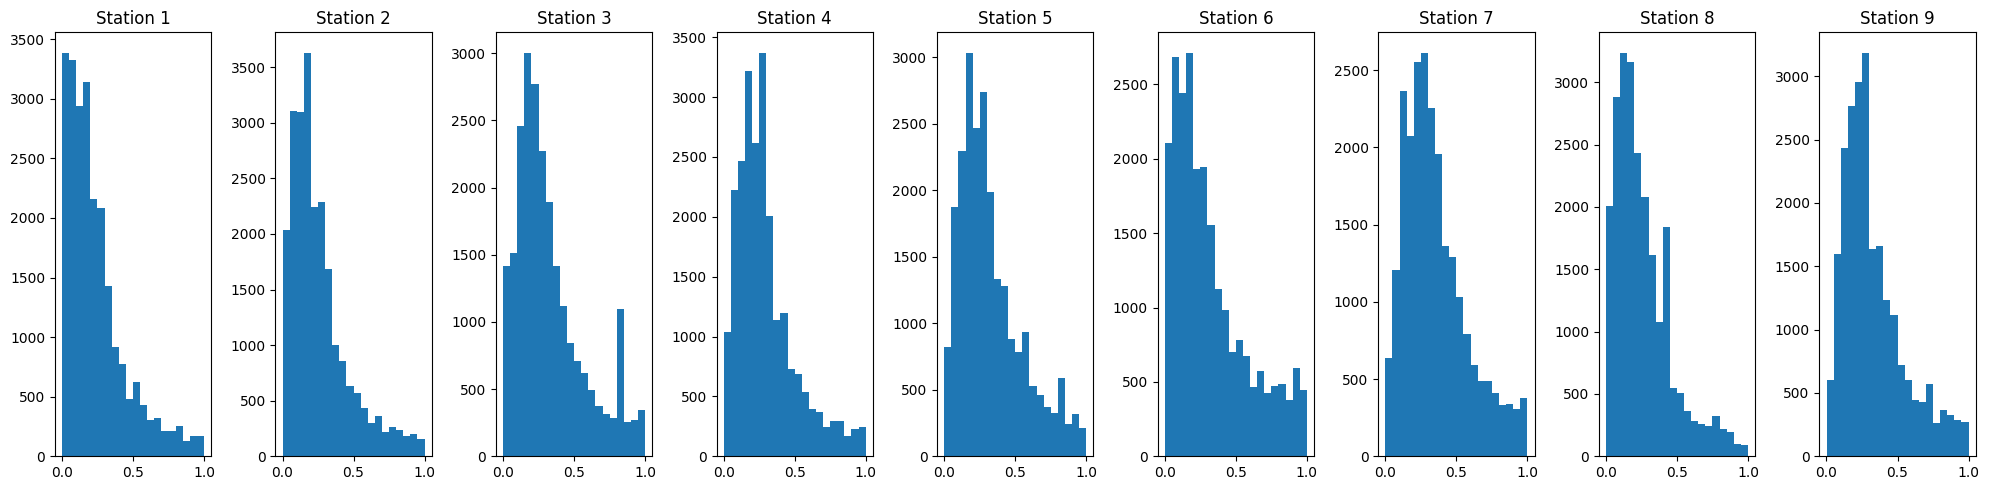

In [28]:
# plot station data distributions

station_groups = df.groupby('Station')['PM2.5']

fig, axes = plt.subplots(1, 9, figsize=(20, 5))

for i, (station, data) in enumerate(station_groups):
    axes[i].hist(data, bins=20)
    axes[i].set_title(f'Station {station}')

plt.tight_layout()
plt.show()


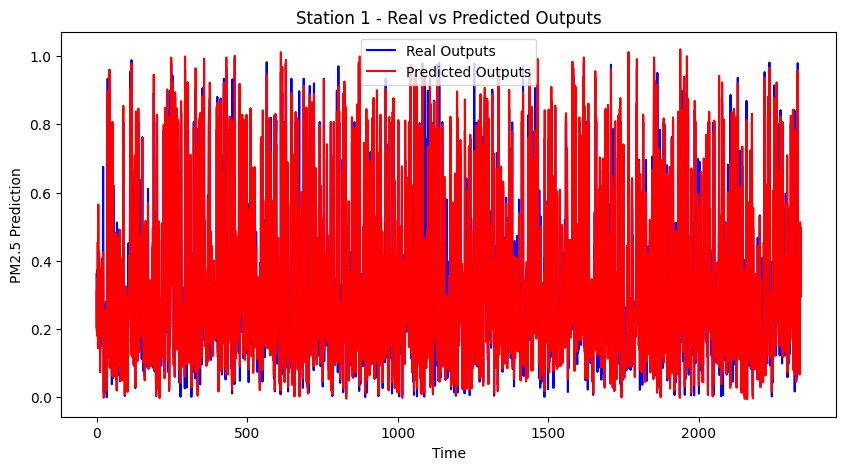

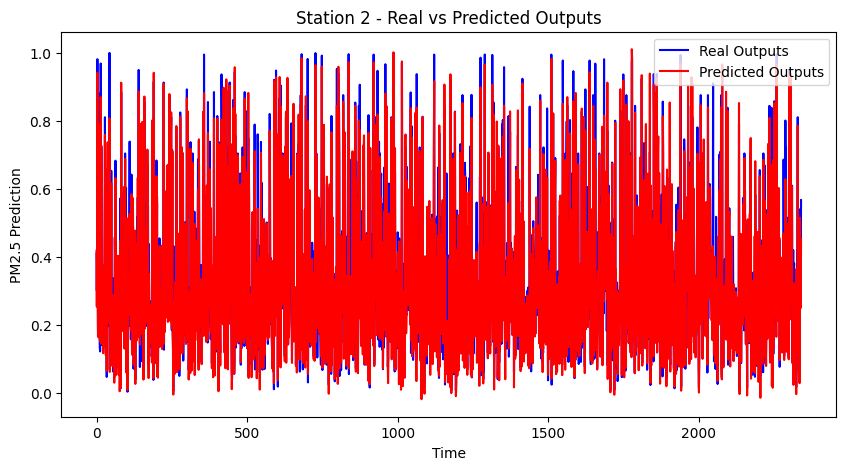

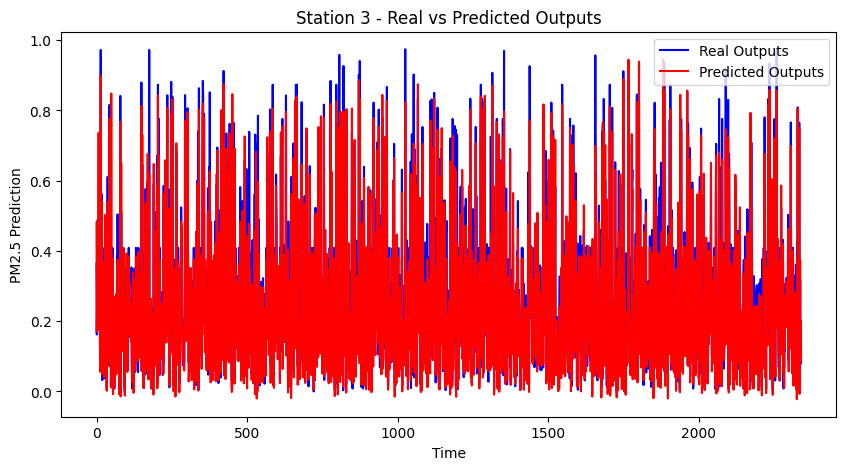

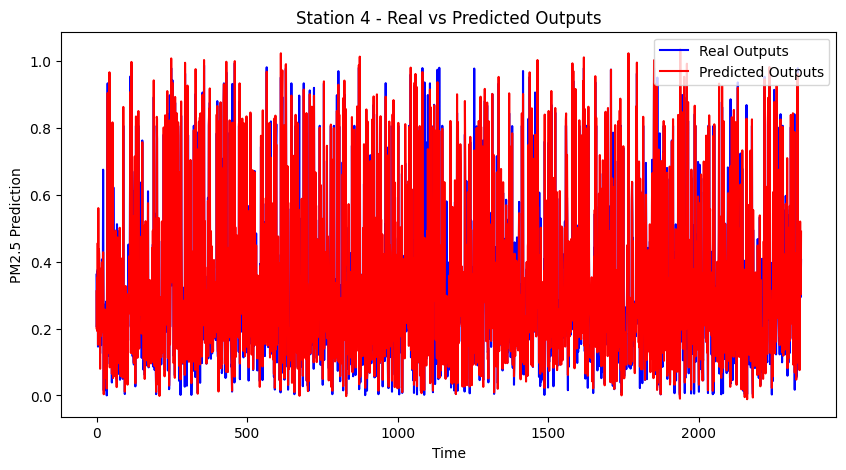

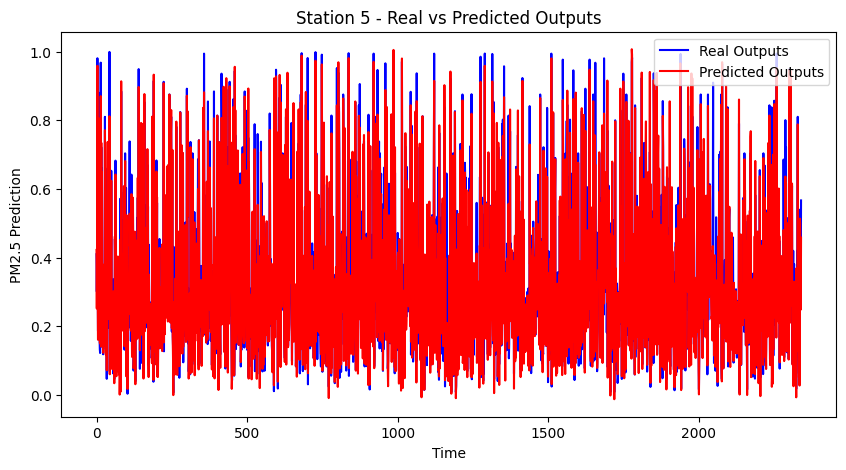

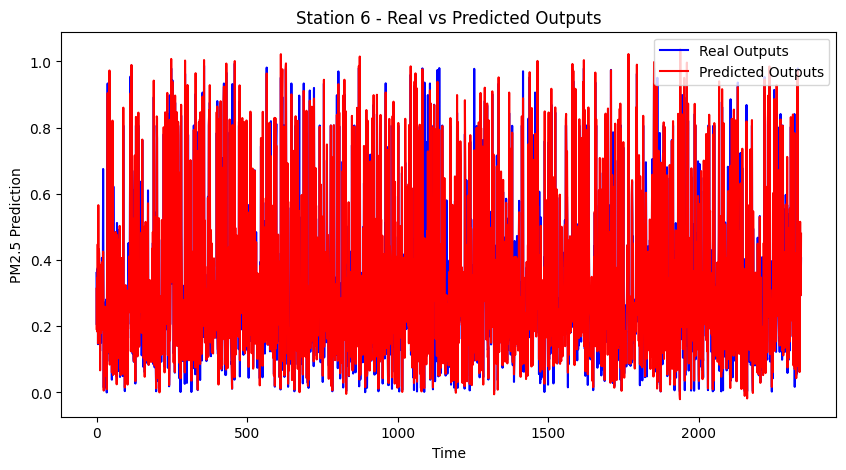

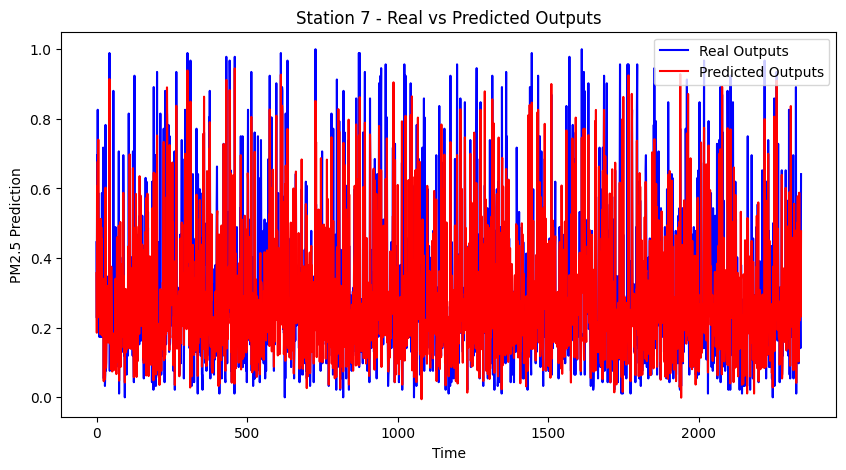

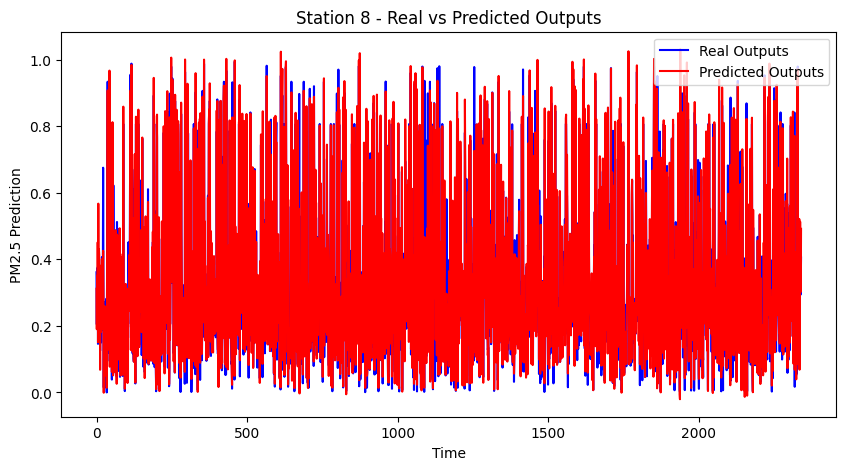

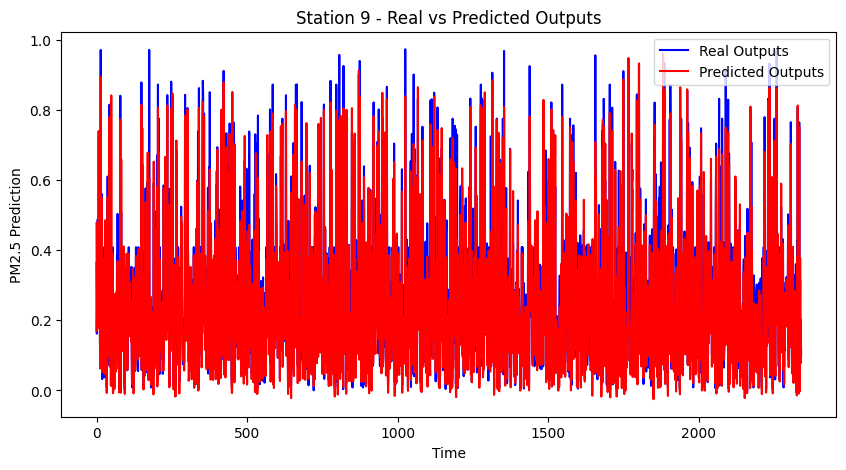

In [29]:
model.eval()

# Initialize lists to store real and predicted outputs
real_outputs = []
predicted_outputs = []

# Disable gradient calculations (for inference only)
with torch.no_grad():
    for inputs, aux_inputs, targets in val_loader:
        inputs, aux_inputs, targets = inputs.to(device), aux_inputs.to(device), targets.to(device)
        preds = model(inputs, aux_inputs)

        # Forward pass through the model to get predictions

        # Ensure the predictions are reshaped correctly to (batch_size, 9, 1)
        preds = preds.view(-1, 9, 1)

        # Store the real and predicted outputs (detach from GPU if necessary)
        real_outputs.append(targets.cpu().numpy())
        predicted_outputs.append(preds.cpu().numpy())

# Convert lists to numpy arrays
real_outputs = np.concatenate(real_outputs, axis=0)
predicted_outputs = np.concatenate(predicted_outputs, axis=0)

# Plotting continuous real vs predicted outputs for each station
for station_idx in range(9):
    plt.figure(figsize=(10, 5))
    plt.plot(real_outputs[:, station_idx, 0], label='Real Outputs', color='blue')
    plt.plot(predicted_outputs[:, station_idx, 0], label='Predicted Outputs', color='red')
    plt.title(f'Station {station_idx+1} - Real vs Predicted Outputs')
    plt.xlabel('Time')
    plt.ylabel('PM2.5 Prediction')
    plt.legend()
    plt.show()

In [58]:
df =  pd.read_csv(os.path.join(base_address, 'PM2.5_preprocessed_data.csv'))
df = df.sort_values(by=['Station', 'Date'], ascending=[True, True])

lower_bound = 4
upper_bound = 96

remove_outliers(lower_bound, upper_bound, df)

Number of outliers replaced: 15438


In [60]:
daily_df = df

daily_df['Date'] = pd.to_datetime(daily_df['Date'])

daily_df = daily_df.groupby([daily_df['Station'], daily_df['Date'].dt.date])['PM2.5'].mean().reset_index()

daily_df.columns = ['Station', 'Date', 'PM2.5']

daily_df.head()

,Station,Date,PM2.5
0,1,2018-08-14,16.333333
1,1,2018-08-15,21.111111
2,1,2018-08-16,13.933333
3,1,2018-08-17,12.125000
4,1,2018-08-18,12.000000


In [61]:
aux_df = pd.read_csv(os.path.join(base_address, 'IsfMet.csv'))
aux_df['date'] = aux_df['date'].apply(append_time_if_missing)
aux_df['date'] = pd.to_datetime(aux_df['date'])
aux_df = aux_df[aux_df['date'].isin(df['Date'])]
aux_df = aux_df[['date', 'ws', 'wd', 'air_temp']]
aux_df = aux_df.ffill().bfill()

aux_df.head()

,date,ws,wd,air_temp
5412,2018-08-14 12:00:00,3.40,344.936731,35.933333
5413,2018-08-14 13:00:00,2.60,144.114473,36.000000
5414,2018-08-14 14:00:00,2.10,55.000000,35.500000
5415,2018-08-14 15:00:00,6.20,55.000000,33.733333
5416,2018-08-14 16:00:00,7.75,46.002444,30.500000


In [62]:
def weighted_mean(x, weights):
    return (x * weights).sum() / weights.sum()

daily_aux = aux_df.groupby(aux_df['date'].dt.date).apply(
    lambda x: pd.Series({
        'mean_ws': x['ws'].mean(),
        'mean_wd': weighted_mean(x['wd'], x['ws']),
        'mean_air_temp': x['air_temp'].mean()
    })
).reset_index()

daily_aux.head()


,date,mean_ws,mean_wd,mean_air_temp
0,2018-08-14,3.640278,146.212015,28.083333
1,2018-08-15,3.372222,139.762127,27.933333
2,2018-08-16,2.348889,129.748026,30.773333
3,2018-08-17,2.323611,177.355953,28.191667
4,2018-08-18,2.974638,139.487317,28.122464


In [141]:
time_lag = 40
pred_horizon = 1
num_epochs = 800
batch_size = 32
number_of_similars = 5

In [142]:
# create datasets

inputs, outputs, aux = prepare_data(daily_df, daily_aux, time_lag, pred_horizon)

train_inputs, temp_inputs, train_outputs, temp_outputs, train_aux, temp_aux = train_test_split(inputs, outputs, aux, test_size=0.2, random_state=42, shuffle=True)
val_inputs, test_inputs, val_outputs, test_outputs, val_aux, test_aux = train_test_split(temp_inputs, temp_outputs, temp_aux, test_size=0.5, random_state=42, shuffle=True)

print(f"Shape of pm2.5 data: {train_inputs[0].shape}")
print(f"Shape of aux data: {train_aux[0].shape}")

auxilary data length: 1208
PM2.5 data length: 1208
Shape of pm2.5 data: (9, 5, 40)
Shape of aux data: (40, 3)


In [143]:
# Create TensorDataset and DataLoader for training and validation
train_dataset = PM25Dataset(train_inputs, train_aux, train_outputs)
val_dataset = PM25Dataset(val_inputs, val_aux, val_outputs)
test_dataset = PM25Dataset(test_inputs, test_aux, test_outputs)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [144]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [148]:
# Define model, loss function, and optimizer
model = CNN_GRU_Model(time_lag=time_lag, pred_horizon=pred_horizon, gru_layers=4)
model = model.to(device)
criterion = nn.L1Loss()
learning_rate = 0.01
momentum = 0.9

optimizer = optim.SGD(model.parameters(), lr=learning_rate, momentum=momentum)

In [149]:
(train_loss_history, val_loss_history, trained_epochs) = model.train_model_early_stop(num_epochs, train_loader, val_loader,
                                                                                      batch_size, optimizer, criterion, device, patience=15)

Training: 100%|██████████| 30/30 [00:00<00:00, 31.96it/s, train loss=0.109]


Epoch [1/800], Train Loss: 0.1941, Val Loss: 0.1509, R2_Score: -0.0691


Training: 100%|██████████| 30/30 [00:00<00:00, 33.75it/s, train loss=0.0905]


Epoch [2/800], Train Loss: 0.1430, Val Loss: 0.1457, R2_Score: -0.0182


Training: 100%|██████████| 30/30 [00:00<00:00, 33.43it/s, train loss=0.16]


...

Epoch [93/800], Train Loss: 0.1088, Val Loss: 0.1179, R2_Score: 0.2273


Training: 100%|██████████| 30/30 [00:00<00:00, 33.37it/s, train loss=0.131]


Epoch [94/800], Train Loss: 0.1082, Val Loss: 0.1123, R2_Score: 0.3875


Training: 100%|██████████| 30/30 [00:00<00:00, 32.83it/s, train loss=0.084]


Epoch [95/800], Train Loss: 0.1036, Val Loss: 0.1187, R2_Score: 0.2192
Early stopping triggered after 95 epochs
Total Training Time: 97.49 seconds


In [150]:
print(sum(model.calculate_r2_score(test_loader)) / 9)

0.1833630402882894


In [151]:
r2_scores = model.calculate_r2_score(test_loader)

for i, r2 in enumerate(r2_scores):
    print(f'R² for station {i+1}: {r2:.4f}')

print(f'Mean of R² scores: {sum(r2_scores)/len(r2_scores):.4f}')


R² for station 1: 0.2870
R² for station 2: 0.1589
R² for station 3: 0.0305
R² for station 4: 0.2802
R² for station 5: 0.1395
R² for station 6: 0.2929
R² for station 7: 0.1640
R² for station 8: 0.2882
R² for station 9: 0.0092
Mean of R² scores: 0.1834


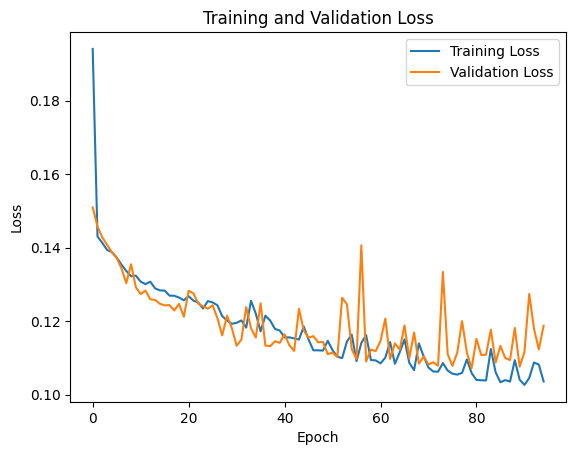

In [152]:
plt.figure()
plt.plot(train_loss_history, label='Training Loss')
plt.plot(val_loss_history, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

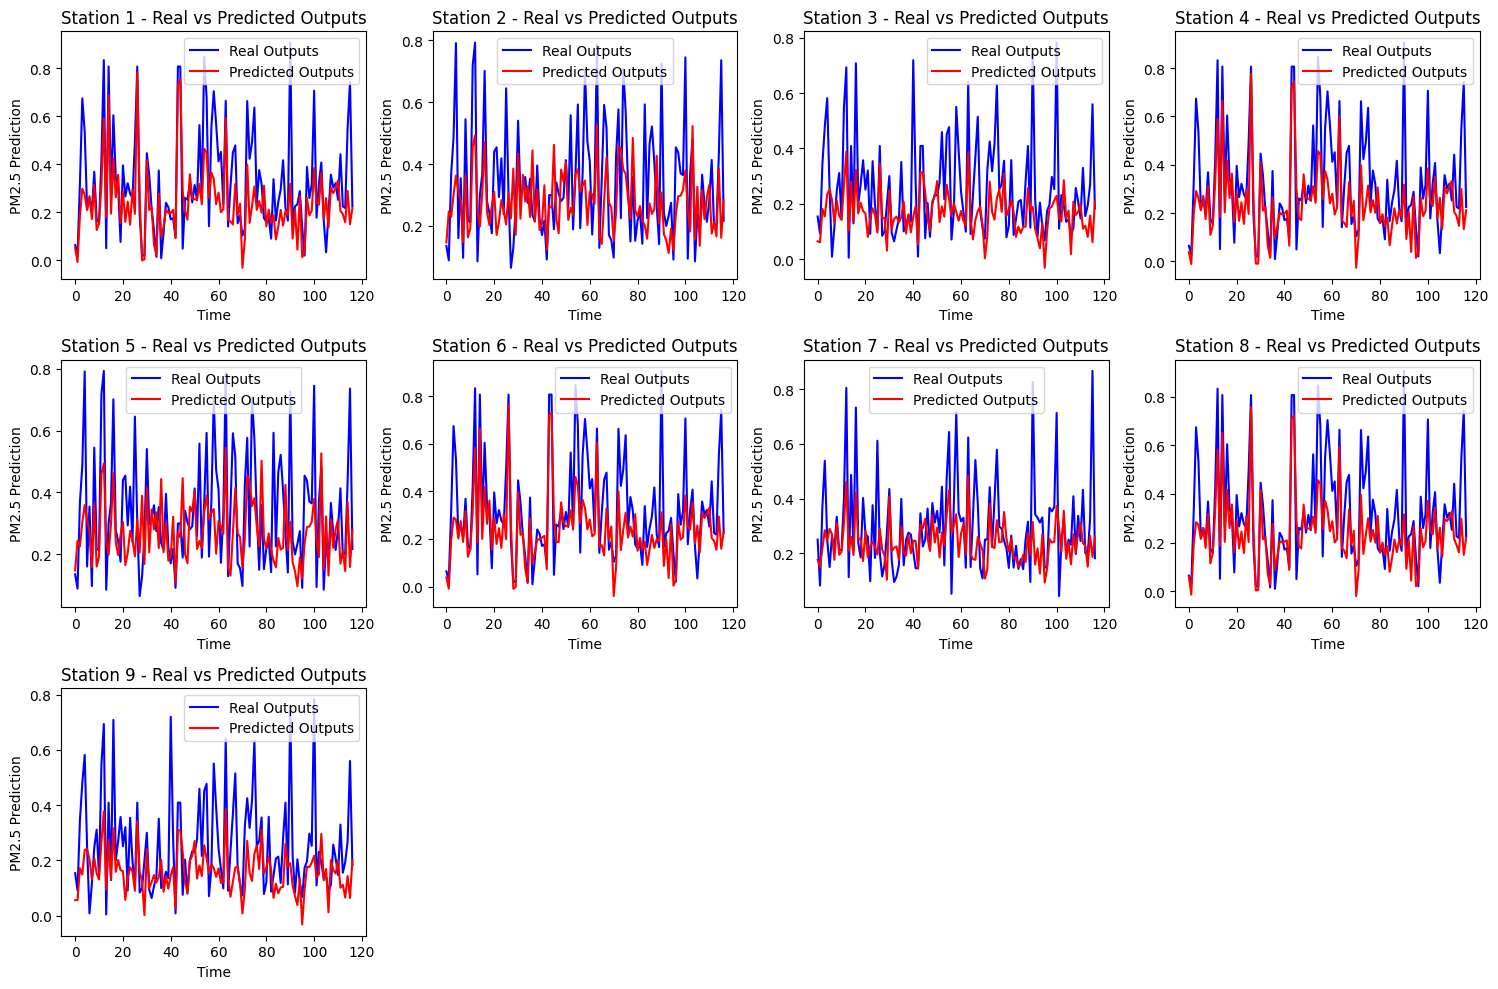

In [153]:
model.eval()

real_outputs = []
predicted_outputs = []

with torch.no_grad():
    for inputs, aux_inputs, targets in val_loader:
        inputs, aux_inputs, targets = inputs.to(device), aux_inputs.to(device), targets.to(device)
        preds = model(inputs, aux_inputs)

        preds = preds.view(-1, 9, 1)

        real_outputs.append(targets.cpu().numpy())
        predicted_outputs.append(preds.cpu().numpy())

real_outputs = np.concatenate(real_outputs, axis=0)
predicted_outputs = np.concatenate(predicted_outputs, axis=0)


fig, axes = plt.subplots(3, 4, figsize=(15, 10))
axes = axes.ravel()

for station_idx in range(9):
    ax = axes[station_idx]  # Select the current axis
    ax.plot(real_outputs[:, station_idx, 0], label='Real Outputs', color='blue')
    ax.plot(predicted_outputs[:, station_idx, 0], label='Predicted Outputs', color='red')
    ax.set_title(f'Station {station_idx+1} - Real vs Predicted Outputs')
    ax.set_xlabel('Time')
    ax.set_ylabel('PM2.5 Prediction')
    ax.legend()

for i in range(9, 12):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()